# Netflix × IMDb: Analysis and Charts

This notebook creates charts for the main findings of the project.
All data comes from the SQLite database `netflix.db`, created with the scripts in `scripts/` and `sql/`.

Connection to Database

In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../netflix.db")
pd.read_sql("select count(*) as titles from netflix_clean", conn)

,titles
0,8807


## 1. Movies vs TV shows over time

How many movies and TV shows were added to Netflix each year?
Years before 2015 are skipped, because Netflix added very few titles then.

In [8]:
query = """
select
    year_added,
    count(case when "type" = 'Movie' then 1 end) as movies,
    count(case when "type" = 'TV Show' then 1 end) as tv_shows,
    round(100.0 * count(case when "type" = 'TV Show' then 1 end) / count(*), 1) as tv_show_pct,
    round(100.0 * count(case when "type" = 'Movie' then 1 end) / count(*), 1) as movies_pct
from netflix_clean
where year_added >= 2015
group by year_added
order by year_added
"""
df_years = pd.read_sql(query, conn)
df_years

,year_added,movies,tv_shows,tv_show_pct,movies_pct
0,2015,56,26,31.7,68.3
1,2016,253,176,41.0,59.0
2,2017,839,349,29.4,70.6
3,2018,1237,412,25.0,75.0
4,2019,1424,592,29.4,70.6
5,2020,1284,595,31.7,68.3
6,2021,993,505,33.7,66.3


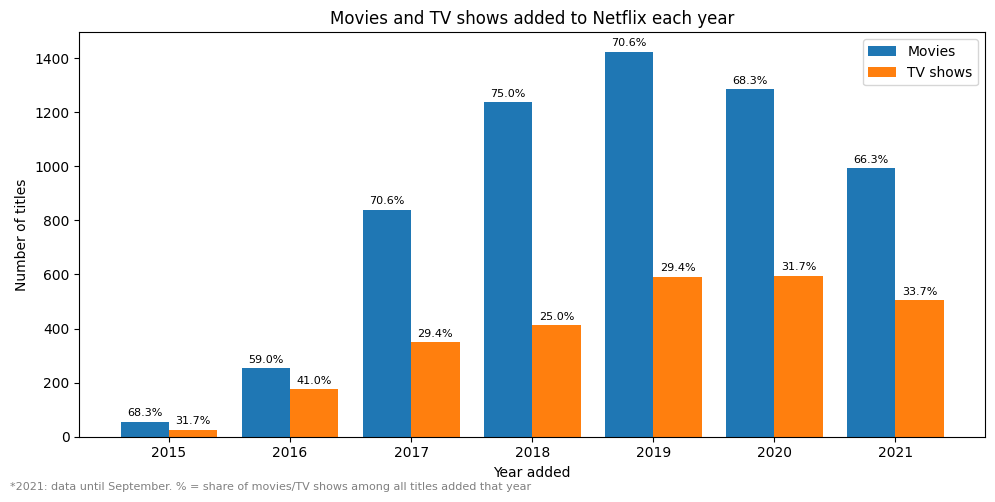

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

width = 0.4                       
x = df_years["year_added"]

# Movies on left, TV shows on right
ax.bar(x - width/2, df_years["movies"], width, label="Movies")
ax.bar(x + width/2, df_years["tv_shows"], width, label="TV shows")

# percent written above each bar
for _, row in df_years.iterrows():
    ax.text(row["year_added"] + width/2, row["tv_shows"] + 20,
            f"{row['tv_show_pct']}%", ha="center", fontsize=8)
    ax.text(row["year_added"] - width/2, row["movies"] + 20,
            f"{row['movies_pct']}%", ha="center", fontsize=8)

ax.set_title("Movies and TV shows added to Netflix each year")
ax.set_xlabel("Year added")
ax.set_ylabel("Number of titles")
ax.set_xticks(x)
ax.legend()

fig.text(0.01, 0.01, "*2021: data until September. % = share of movies/TV shows among all titles added that year",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/01_movies_vs_tv.png", dpi=150)
plt.show()

**Findings:**
- Since 2016 Netflix added many more titles each year, most of them in 2019 (2,016).
- The share of TV shows dropped from 41% (2016) to 25% (2018), then grew every year to 33.7% (2021).
- 2021 is not a full year (the data ends in September), so we compare percentages, not numbers.

## 2. New movies or older catalog?

How many of the movies added each year were new (released max 1 year before)?
Only movies are used, because for TV shows `release_year` is often the year of the latest season.

In [19]:
query = """
select year_added, count(title) as titles,
    round(100.0 * count(case when (year_added-release_year) <=1 then 1 end) / count(*), 1) as new_pct
from netflix_clean
where "type" = 'Movie' and year_added >= 2015
group by year_added
order by year_added;"""
df_movies = pd.read_sql(query, conn)
df_movies

,year_added,titles,new_pct
0,2015,56,89.3
1,2016,253,75.5
2,2017,839,62.8
3,2018,1237,49.0
4,2019,1424,45.9
5,2020,1284,46.0
6,2021,993,40.0


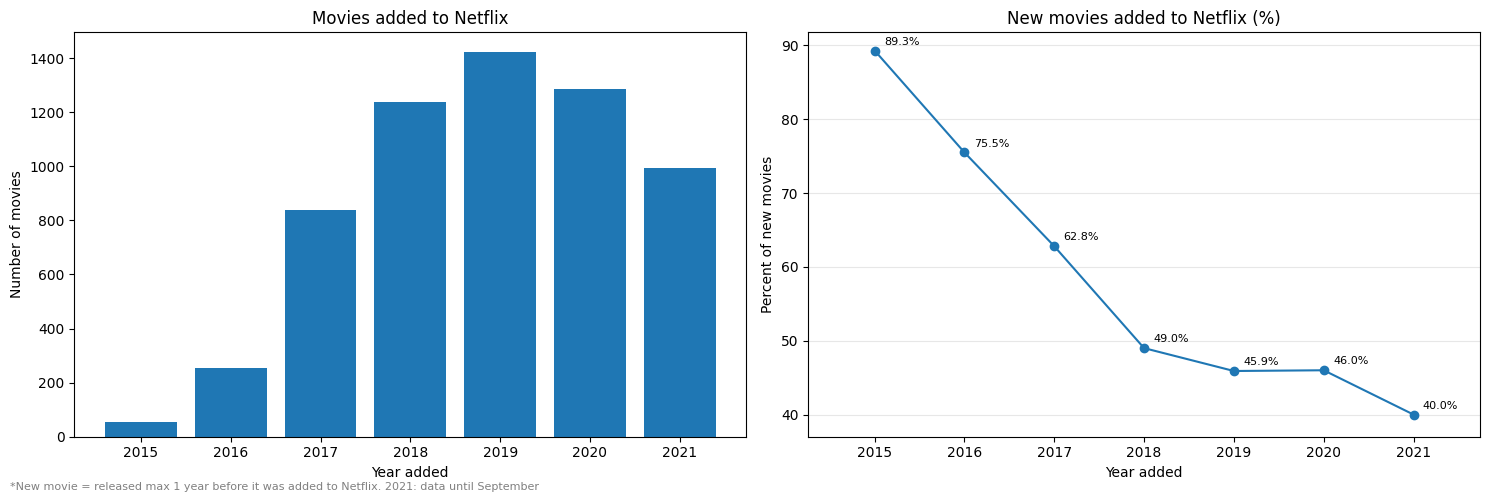

In [69]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

x = df_movies["year_added"]

#First chart
ax1.bar(x, df_movies["titles"])
ax1.set_title("Movies added to Netflix")
ax1.set_ylabel("Number of movies")
ax1.set_xlabel("Year added")


#Second chart
ax2.plot(x,df_movies["new_pct"],marker="o")

for _, row in df_movies.iterrows():
    ax2.text(row["year_added"]+0.3, row["new_pct"] + 0.8,   
             f"{row['new_pct']}%", ha="center", fontsize=8)

ax2.set_ylim(37)
ax2.set_title("New movies added to Netflix (%)")
ax2.set_ylabel("Percent of new movies")
ax2.set_xlabel("Year added")
ax2.set_xticks(x)
ax2.grid(axis="y", alpha=0.3)

fig.text(0.01, 0.01, "*New movie = released max 1 year before it was added to Netflix. 2021: data until September",
         fontsize=8, color="gray")
plt.tight_layout()
plt.savefig("../images/02_new_movies.png", dpi=150)
plt.show()

**Findings:**
- In 2015, 89% of movies added to Netflix were new. In 2021 only 40%.
- Netflix adds more and more older movies to its catalog.
- But the data shows only titles still on Netflix in 2021. Older movies added in early years
  could already be removed, so early years may look "newer" than they really were.

## 3. Genres

Which genres have the best rated titles in IMDb?
Movies and TV shows are compared separately, because TV shows in general get higher ratings.
Only titles with at least 100 votes and genres with at least 50 titles are used.

In [77]:
query_movie = """select g.genre, count(n.title) as movies, round(avg(n.imdb_rating),2) as avg_rating
from netflix_clean n 
join netflix_genres g on n.show_id=g.show_id
where n.imdb_votes >= 100 and n."type" = 'Movie'
group by g.genre
having count(*)>=50
order by avg_rating desc;"""

query_show = """select g.genre, count(n.title) as tv_shows, round(avg(n.imdb_rating),2) as avg_rating
from netflix_clean n 
join netflix_genres g on n.show_id=g.show_id
where n.imdb_votes >= 100 and n."type" = 'TV Show'
group by g.genre
having count(*)>=50
order by avg_rating desc;"""

df_genres_movies = pd.read_sql(query_movie,conn)
df_genres_shows = pd.read_sql(query_show,conn)

combined_df = pd.concat([df_genres_movies, df_genres_shows], axis=1, keys=["Movies", "TV shows"])
combined_df

Movies                                     TV shows  \
                       genre movies avg_rating                      genre   
0             Classic Movies    108       7.34            Korean TV Shows   
1              Documentaries    645       6.93               Anime Series   
2                Cult Movies     65       6.84        Science & Nature TV   
3            Stand-Up Comedy    268       6.81           British TV Shows   
4              Sports Movies    181       6.58                  TV Dramas   
5                     Dramas   2044       6.42      TV Action & Adventure   
6           Music & Musicals    286       6.41                 Docuseries   
7               LGBTQ Movies     91       6.36             Crime TV Shows   
8         Independent Movies    684       6.30          Romantic TV Shows   
9       International Movies   2106       6.22              Teen TV Shows   
10           Romantic Movies    524       6.08        TV Sci-Fi & Fantasy   
11          Sci-Fi & Fantasy    217       6.01     International TV Shows   
12        Action & Adventure    751       6.00                TV Comedies   
13  Children & Family Movies    443       5.97               TV Mysteries   
14      Faith & Spirituality     51       5.96  Spanish-Language TV Shows   
15                  Comedies   1367       5.94                  TV Horror   
16                 Thrillers    518       5.90                 Reality TV   
17             Horror Movies    314       5.33                   Kids' TV   

                        
   tv_shows avg_rating  
0       102       7.47  
1       138       7.39  
2        71       7.37  
3       193       7.33  
4       569       7.32  
5       141       7.32  
6       295       7.32  
7       394       7.27  
8       243       7.22  
9        63       7.20  
10       71       7.20  
11      950       7.19  
12      446       7.09  
13       91       7.07  
14      128       6.96  
15       63       6.90  
16      201       6.58  
17      318       6.58

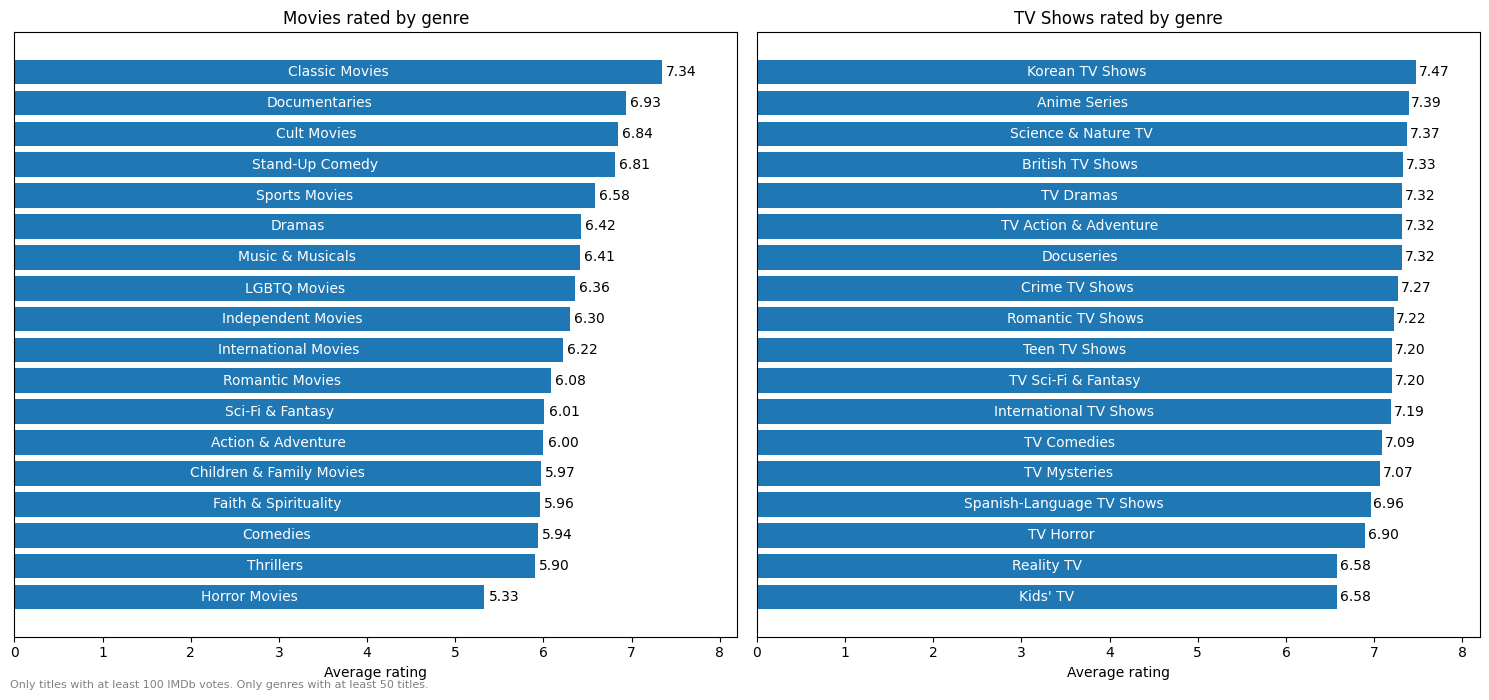

In [108]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(15, 7), sharex=True)

x1 = df_genres_movies["genre"]
x2 = df_genres_shows["genre"]

#First chart
bars1 = ax1.barh(x1, df_genres_movies["avg_rating"])
ax1.set_title("Movies rated by genre")
ax1.set_ylabel("Genre")
ax1.set_xlabel("Average rating")
ax1.bar_label(bars1,labels = x1, label_type ='center',color='white')
ax1.bar_label(bars1, label_type ='edge',color='black',padding=3,fmt="%.2f")
ax1.yaxis.set_visible(False)
ax1.invert_yaxis()
ax1.set_xlim(0, 8.2)

#Second chart
bars2 = ax2.barh(x2, df_genres_shows["avg_rating"])
ax2.set_title("TV Shows rated by genre")
ax2.set_ylabel("Genre")
ax2.set_xlabel("Average rating")
ax2.bar_label(bars2,labels = x2, label_type ='center',color='white',)
ax2.bar_label(bars2, label_type ='edge',color='black',padding=2,fmt="%.2f")
ax2.yaxis.set_visible(False)
ax2.invert_yaxis()

fig.text(0.01, 0.01, "Only titles with at least 100 IMDb votes. Only genres with at least 50 titles.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/03_genres.png", dpi=150)
plt.show()

**Findings:**
- TV shows get higher ratings than movies: even the worst rated TV genres (6.58)
  are on the level of good movie genres.
- Movies: best rated are Classic Movies (7.34), Documentaries (6.93) and Stand-Up Comedy (6.81).
  Popular genres like Comedies, Thrillers and Horror Movies (5.33) are at the bottom.
- TV shows: best rated are Korean TV Shows (7.47) and Anime Series (7.39).